In [1]:
import numpy as np
import matplotlib.pyplot as plt

### my modules
from fast_volume_align_ot import utils, plots, transforms, distances

In [2]:
def points_to_voxels(p, L):
    """
    converts points (x,y,z) in [-1,1]^3 to voxel indices in [0, L-1]^3

    input points: p in 3 X n_points 
    """

    ### TODO:
    ### - check that this works with Cartesian rotated points
    ### - add option to return the voxel points

    ### figure out best conventions, currently:
    ### - Cartesian x --> Numpy z (axis=0)
    ### - Cartesian y --> Numpy y (axis=1)
    ### - Cartesian z --> Numpy x (axis=2)

    f = np.zeros((L,L,L))
    
    pn = (p + 1) / 2 * (L-1)
    v = np.floor(pn.T).astype('int')

    vx = v[:, 0]
    vy = v[:, 1]
    vz = v[:, 2]

    f[vx, vy, vz] = 1
    
    return f

In [ ]:
# L = 3

# p = np.array([[0, 0, -1, 0, 1], 
#               [0, 0, -1, 0, -1], 
#               [0, 0, 1, 0, -1]])

In [ ]:
# L = 3

# f = np.zeros((L,L,L))

# # p = np.array([[1, -1, -1], 
# #               [-1, 1, -1], 
# #               [-1, -1, 1]])

# ### Cartesian x --> Numpy z (axis=0)
# p = np.array([[1, 0, 0], 
#               [-1, 0, 0], 
#               [-1, 0, 0]])

# ### Cartesian y --> Numpy y (axis=1)
# p = np.array([[0, -1, 0], 
#               [0, 1, 0], 
#               [0, -1, 0]])

# ### Cartesian z --> Numpy x (axis=2)
# p = np.array([[0, 0, -1, 0], 
#               [0, 0, -1, 0], 
#               [0, 0, 1, 0]])

In [ ]:
# vx = v[:, 0]
# vy = v[:, 1]
# vz = v[:, 2]

# f[vx, vy, vz] = 1

In [3]:
p = np.array([[0, -0.33, 0.33], [0, 0, -0.33], [0, 0.33, 0.33]]).T

R = transforms.rotate_x(np.pi/2)

q = R @ p

In [5]:
p

array([[ 0.  ,  0.  ,  0.  ],
       [-0.33,  0.  ,  0.33],
       [ 0.33, -0.33,  0.33]])

	 original


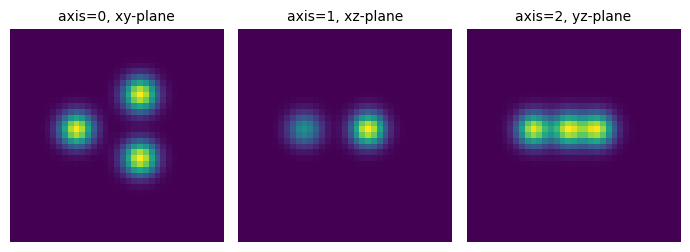

	 rotated


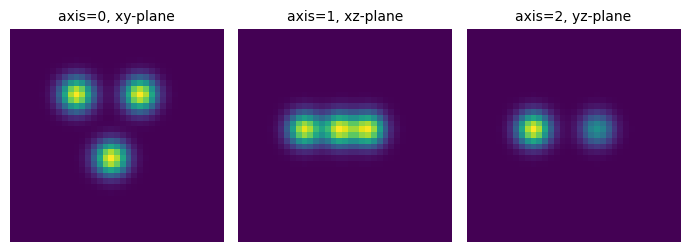

In [4]:
L = 37
f = points_to_voxels(p, L)
g = points_to_voxels(q, L)

sigma = 2
z = utils.generate_centered_gaussian(L=L, d=3, sigma=sigma)

f = utils.signal_convolution(f, z)
g = utils.signal_convolution(g, z)

print('\t original')
plots.orthogonal_2D_projection_plot(f)
print('\t rotated')
plots.orthogonal_2D_projection_plot(g)